# Auto DS: figures of Lesson 10.01

- This notebook generates the figures of the slides
  `Lesson10.01_Auto_DS.smd` from simulated data, and saves them as PNG files
- The pedagogical arc:
  - AutoML search: a search over many configurations raises the validation
    score faster than the holdout score
  - Auto label generation: the triple barrier method, and the label choice as
    one more dimension of the search
  - Experiment tracking and guardrails: the effective number of trials, and
    the holdout score that rises with every look

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hintrospection as hintros
import helpers.hmatplotlib as hmatplo
import helpers.hnotebook as hnotebook

import L10_01_auto_ds_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /Users/saggese/src/venv/client_venv.helpers/lib/python3.11/site-packages/ipykernel_launcher.py -f /private/var/folders/pd/0_nppqrn3cn7936mmhk37gcw0000gn/T/tmp0bp_diop.json --HistoryManager.hist_file=:memory:


In [3]:
# Directory of the figures, and prefix of the markdown reference to paste in the
# slides.
out_dir_name = "figures"
markdown_path_prefix = "book_Modern_AI_for_Finance/lectures_source"

# Figure sizes: a single panel fits a column of a slide, the two-panel figure
# needs more width.
figsize = (6.0, 4.0)
figsize_wide = (7.0, 3.2)

# Seed of all the simulations. Each cell sets its own seed, chosen so that the
# simulated outcome is representative of the average behavior, e.g., the best
# configuration on the validation block of the label search has a holdout
# Sharpe ratio close to 0.
seed = 32

# Part 1: AutoML search

## Cell 1.1: Search overfits the validation score

**Goal**
- Run a random search over models, hyperparameters, and feature subsets, and
  score every trial with a purged and embargoed cross-validation
- See that the best cross-validation score keeps rising with the number of
  trials, while the holdout score of the same configuration flattens

**Description**
- Inputs
  - `n_obs`: number of days, research period plus holdout
  - `n_features`: number of candidate features
  - `n_informative`: number of features that predict the return
  - `signal_coef`: coefficient of each informative feature
  - `n_trials`: number of configurations tried in one search
  - `n_folds`: number of folds of the purged cross-validation
  - `label_horizon`: number of days spanned by one label
  - `embargo`: number of days embargoed after each test block
  - `holdout_frac`: fraction of the days of the final holdout
  - `n_repeats`: number of independent searches that are averaged
  - `seed`: seed of the random number generator

- Panels
  - `Score`: best cross-validation score so far in blue and holdout score of
    that configuration in red, as mean and interquartile band of the
    searches, against the number of trials on a log scale
  - `Oracle`: gray dashed line with the score of the true signal on the
    holdout

Saved figure to 'figures/L10.01.Search_Overfitting.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L10.01.Search_Overfitting.png)


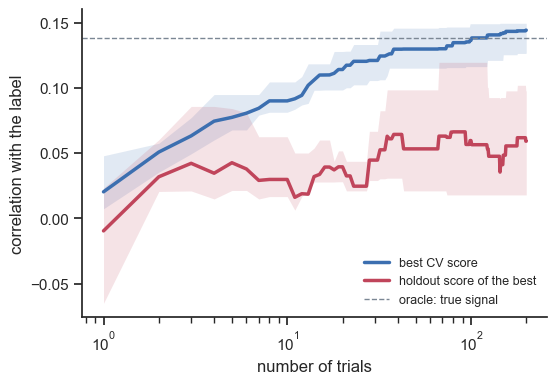

In [4]:
# Plot the cross-validation score and the holdout score of the best trial.
fig = utils.cell1_1_plot_search_overfitting(
    n_obs=2500,
    n_features=30,
    n_informative=3,
    signal_coef=0.06,
    n_trials=200,
    n_folds=5,
    label_horizon=5,
    embargo=5,
    holdout_frac=0.2,
    n_repeats=10,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L10.01.Search_Overfitting.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `signal_coef` from 0.06 to 0
  - Observe the best cross-validation score still reach 0.115 after 200
    trials, while the holdout score of the same configuration stays at -0.04:
    the search finds a good score where there is no signal at all
- Change `n_obs` from 2500 to 10000
  - Observe the gap between the two curves close, from 0.086 to 0.005 after
    200 trials: more days make each fold score less noisy, so the maximum
    over the trials inflates less

**Implementation** `cell1_1_plot_search_overfitting()`
- Simulates persistent features, a return that depends on the first
  `n_informative` features, and a label equal to the sum of the next
  `label_horizon` returns
- Draws each configuration at random: a model family (ridge, decision tree,
  or nearest neighbors), its hyperparameters, and a subset of the features
- Scores each configuration with the mean correlation over the purged and
  embargoed folds of the research period
- Refits the configuration on the research period and scores it on the
  holdout, for illustration only
- Tracks the incumbent, i.e., the configuration with the best cross-validation
  score so far

In [5]:
hintros.print_obj_info(utils.cell1_1_plot_search_overfitting)

- `cell1_1_plot_search_overfitting(*, n_obs: int, n_features: int, n_informative: int, signal_coef: float, n_trials: int, n_folds: int, label_horizon: int, embargo: int, holdout_frac: float, n_repeats: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the CV score and the holdout score of the best trial of a search.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L10_auto_ds/L10_01_auto_ds_utils.py#L327


# Part 2: Auto label generation

## Cell 2.1: Triple barrier method

**Goal**
- Label events by the first barrier that the price path touches: profit
  taking, stop loss, or the end of the holding period
- See that the barrier width changes the label of the same path

**Description**
- Inputs
  - `n_bars`: number of bars of the price path
  - `volatility`: volatility of the return of one bar
  - `horizon`: number of bars until the vertical barrier
  - `barrier_mult`: width of the horizontal barriers, in standard deviations
    of the return over the horizon
  - `starts`: bars where the events begin
  - `seed`: seed of the random number generator

- Panels
  - `Path`: price path in gray, with one box of barriers per event and the
    entry marked in blue
  - `Labels`: the barrier that ends each event is drawn thick, in green for
    +1, in red for -1, and in orange for the vertical barrier

Saved figure to 'figures/L10.01.Triple_Barrier.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L10.01.Triple_Barrier.png)


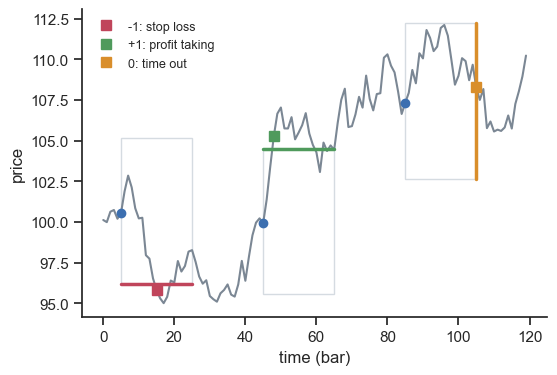

In [6]:
# Plot a price path with the triple barriers of three events.
fig = utils.cell2_1_plot_triple_barrier(
    n_bars=120,
    volatility=0.01,
    horizon=20,
    barrier_mult=1.0,
    starts=[5, 45, 85],
    seed=0,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L10.01.Triple_Barrier.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `barrier_mult` from 1.0 to 0.5
  - Observe the three events end in +1 after only 2 to 4 bars, and the first
    event flip from -1 to +1: the same path gets a different label
- Change `horizon` from 20 to 5
  - Observe the barriers narrow, since their width scales with the square root
    of the horizon, and the three events end in +1 within 4 bars

**Implementation** `cell2_1_plot_triple_barrier()`
- Simulates a Gaussian random walk of the log price
- Sets the half width of the horizontal barriers to
  `barrier_mult * volatility * sqrt(horizon)`
- Scans the path after each start and takes the first bar that crosses the
  upper or the lower barrier, or the bar of the vertical barrier

In [7]:
hintros.print_obj_info(utils.cell2_1_plot_triple_barrier)

- `cell2_1_plot_triple_barrier(*, n_bars: int, volatility: float, horizon: int, barrier_mult: float, starts: List[int], seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot a price path with the triple barriers and the labels of some events.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L10_auto_ds/L10_01_auto_ds_utils.py#L474

## Cell 2.2: Label choice as a hidden trial dimension

**Goal**
- Train one model per label configuration, on returns that contain no signal
  by construction
- See that the best label configuration on the validation block has a high
  Sharpe ratio, and that the same configuration earns about 0 on the holdout

**Description**
- Inputs
  - `n_obs`: number of days
  - `n_features`: number of features
  - `volatility`: daily volatility of the returns
  - `horizons`: label horizons, in days
  - `thresholds`: dead zone of the label, in multiples of the volatility over
    the horizon
  - `train_frac`: fraction of the days used to train the models
  - `valid_frac`: fraction of the days of the validation block
  - `seed`: seed of the random number generator

- Panels
  - `Sharpe ratio`: validation Sharpe ratio of each label configuration as
    blue dots, grouped by horizon, with the best one circled in orange and
    its holdout Sharpe ratio as a red diamond

Saved figure to 'figures/L10.01.Label_Choice.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L10.01.Label_Choice.png)


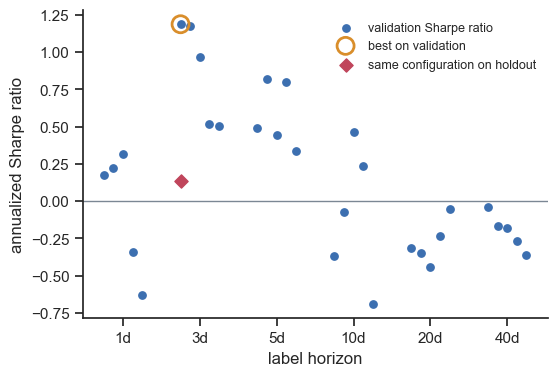

In [8]:
# Plot the validation Sharpe ratio of each label configuration.
fig = utils.cell2_2_plot_label_choice(
    n_obs=2520,
    n_features=10,
    volatility=0.01,
    horizons=[1, 3, 5, 10, 20, 40],
    thresholds=[0.0, 0.25, 0.5, 0.75, 1.0],
    train_frac=0.4,
    valid_frac=0.3,
    seed=5,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L10.01.Label_Choice.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `n_obs` from 2520 to 10080
  - Observe the best validation Sharpe ratio fall from 1.19 to 0.47: a longer
    validation block makes each estimate less noisy, so luck inflates the
    maximum less
- Change `horizons` from six values to `[1]`
  - Observe the best validation Sharpe ratio fall from 1.19 to 0.32: with 5
    configurations instead of 30, the best of the set is closer to 0

**Implementation** `cell2_2_plot_label_choice()`
- Simulates Gaussian daily returns with mean 0 and persistent features that
  are unrelated to them
- Builds each label as the sign of the return over the horizon, with a dead
  zone around 0 that is dropped from the training set
- Fits a logistic regression on the first block and trades the sign of its
  score, so that the position of day `t` earns the return of day `t + 1`
- Computes the annualized Sharpe ratio on the validation block and on the
  holdout block

In [9]:
hintros.print_obj_info(utils.cell2_2_plot_label_choice)

- `cell2_2_plot_label_choice(*, n_obs: int, n_features: int, volatility: float, horizons: List[int], thresholds: List[float], train_frac: float, valid_frac: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the validation Sharpe ratio of one model per label configuration.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L10_auto_ds/L10_01_auto_ds_utils.py#L625


# Part 3: Experiment tracking and guardrails

## Cell 3.1: Effective number of trials

**Goal**
- Cluster the trial returns of a search, and count the clusters as the
  effective number of trials
- See that counting every trial overstates the hurdle of the best Sharpe
  ratio, and that the number of clusters understates it

**Description**
- Inputs
  - `n_clusters`: number of groups of correlated trials
  - `trials_per_cluster`: number of trials in each group
  - `intra_corr`: correlation between two trials of the same group
  - `n_days`: number of days of each trial
  - `cut_corr`: correlation threshold where the clustering tree is cut
  - `n_sims`: number of Monte Carlo repetitions
  - `seed`: seed of the random number generator

- Panels
  - `Correlation`: correlation matrix of the trials, ordered by the leaves of
    the clustering tree
  - `Expected maximum`: expected maximum Sharpe ratio when the number of
    trials is the number of trials, the number of clusters, and the Monte
    Carlo value for the correlated trials

Saved figure to 'figures/L10.01.Effective_Trials.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L10.01.Effective_Trials.png)


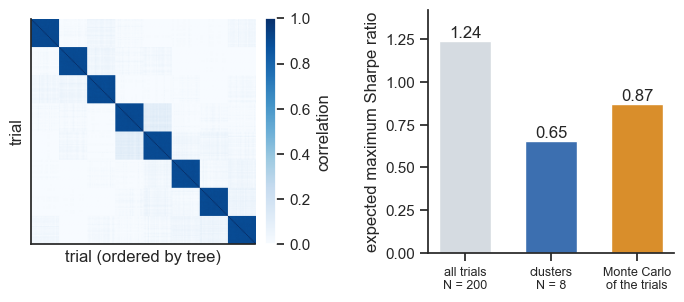

In [10]:
# Plot the correlation of the trials and the expected maximum Sharpe ratio.
fig = utils.cell3_1_plot_effective_trials(
    n_clusters=8,
    trials_per_cluster=25,
    intra_corr=0.9,
    n_days=1260,
    cut_corr=0.5,
    n_sims=300,
    seed=seed,
    figsize=figsize_wide,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L10.01.Effective_Trials.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `intra_corr` from 0.9 to 0.5
  - Observe the clustering find 60 clusters instead of 8, and the hurdle of
    the clusters rise from 0.65 to 1.05, close to the 1.24 of all the trials
- Change `n_clusters` from 8 to 20
  - Observe 500 trials, 20 clusters, and a Monte Carlo maximum of 1.08 that
    again lies between the hurdle of the clusters (0.85) and the one of all
    the trials (1.37)

**Implementation** `cell3_1_plot_effective_trials()`
- Simulates zero-skill trial returns where the trials of one group share a
  common factor
- Clusters the trials with average linkage on the distance
  `sqrt((1 - corr) / 2)` and cuts the tree at `cut_corr`
- Evaluates the false strategy theorem for the number of trials and for the
  number of clusters
- Averages the maximum Sharpe ratio over `n_sims` simulated searches

In [11]:
hintros.print_obj_info(utils.cell3_1_plot_effective_trials)

- `cell3_1_plot_effective_trials(*, n_clusters: int, trials_per_cluster: int, intra_corr: float, n_days: int, cut_corr: float, n_sims: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the correlation of the trials and the expected maximum Sharpe ratio.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L10_auto_ds/L10_01_auto_ds_utils.py#L767


## Cell 3.2: Holdout looks

**Goal**
- Tune a trading rule by looking at the same holdout again and again, on a
  random walk that contains no signal
- See that the holdout Sharpe ratio rises with each look, while fresh data
  stays at about 0

**Description**
- Inputs
  - `n_days`: number of days of the holdout and of the fresh data
  - `volatility`: daily volatility of the returns
  - `n_looks`: number of looks at the holdout
  - `max_slow`: largest window of the slow moving average
  - `n_sims`: number of independent researchers that are averaged
  - `seed`: seed of the random number generator

- Panels
  - `Looks`: holdout Sharpe ratio of the tuned rule in red and Sharpe ratio of
    the same rule on fresh data in blue, as mean and interquartile band of the
    researchers, against the number of looks

Saved figure to 'figures/L10.01.Holdout_Looks.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L10.01.Holdout_Looks.png)


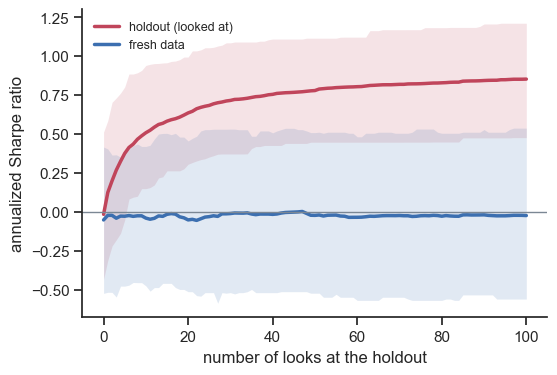

In [12]:
# Plot the holdout Sharpe ratio against the number of looks.
fig = utils.cell3_2_plot_holdout_looks(
    n_days=504,
    volatility=0.01,
    n_looks=100,
    max_slow=100,
    n_sims=200,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L10.01.Holdout_Looks.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `n_days` from 504 to 2520
  - Observe the holdout Sharpe ratio after 100 looks fall from 0.85 to 0.41,
    while fresh data stays at 0.01: a longer holdout is harder to overfit, and
    not immune
- Change `n_looks` from 100 to 20
  - Observe the holdout Sharpe ratio end at 0.68, which is 80% of the 0.85
    reached after 100 looks: the first looks matter most

**Implementation** `cell3_2_plot_holdout_looks()`
- Simulates a random walk for the holdout and another one for the fresh data
- Starts from a random pair of windows of a moving-average crossover
- Each look tries a nearby pair of windows and keeps it when the holdout
  Sharpe ratio improves
- Scores the kept pair on the fresh data after each look

In [13]:
hintros.print_obj_info(utils.cell3_2_plot_holdout_looks)

- `cell3_2_plot_holdout_looks(*, n_days: int, volatility: float, n_looks: int, max_slow: int, n_sims: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the holdout Sharpe ratio of a rule tuned by repeated looks.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L10_auto_ds/L10_01_auto_ds_utils.py#L892
